# 08 — Atributos numéricos na v2_full sem F4: os 3 experimentos refeitos + lentificação
Mesmo protocolo do notebook 07, trocando a base:
- **v2_full**: ICA (infomax estendida) + **ICLabel** removendo olho/músculo/coração/linha/canal (prob. ≥ 0,7) +
  **escala de amplitude por participante** — a variante recomendada no notebook 06;
- **sem F4**: o eletrodo sai antes da referência média e da ICA (18 canais). F4 tem atenuação de alta frequência
  (~10× menos beta que F3 em vários participantes, mais no TCM) — tratado como problema técnico.

| Experimento | Atributos |
|---|---|
| Referência | clássicos (20 × 18 = 360) |
| Exp. 1 | só numéricos (28 × 18 = 504) |
| Exp. 2 | todos (864) |
| Exp. 3a | todos → seleção não supervisionada |
| Exp. 3b | todos → mRMR supervisionado aninhado (referência) + clusters com os atributos estáveis (**otimista**) |

Inclui a seção **Indicadores de lentificação**, que testa diretamente a hipótese de lentificação do EEG no TCM.
Resultados do notebook 07 (v0, 19 canais) em `reports/07_*.csv` para comparação.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mne
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

from src.data_io import ROOT, PROCESSED_DIR, SCALP_CHANNELS, REGION, mne_info
from src.pipeline import VARIANTS, build_features, load_variant, load_numericos
from src.features import feature_families
from src.clustering import to_pca, balance_windows, k_sweep, best_k, evaluate
from src.selection import drop_quasi_constant, select_unsupervised, nested_mrmr_loso
from src.evaluation import auc_ci, loso_logreg, mann_whitney_fdr

FIG = ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
SEED = 0
ID = ["subject", "group", "sex", "window"]

BASE = "v2_full_semF4"   # variante de pré-processamento (src/pipeline.VARIANTS)
OUT = "08"    # prefixo dos arquivos de saída
if not (PROCESSED_DIR / BASE / "features_numericos.parquet").exists():
    build_features(VARIANTS[BASE], verbose=False)
clas, log = load_variant(BASE)
num = load_numericos(BASE)
feat_w = clas.merge(num, on=ID, validate="one_to_one")
CLASS = [c for c in clas.columns if c not in ID]
NUM_ALL = [c for c in num.columns if c not in ID]
_suf = {c.split("__")[1] for c in clas.columns if "__" in c}
CH = [c for c in SCALP_CHANNELS if c in _suf]   # canais presentes nesta variante
print("base:", BASE, "| canais:", len(CH), "| janelas:", len(feat_w), "| clássicos:", len(CLASS), "| numéricos:", len(NUM_ALL))

base: v2_full_semF4 | canais: 18 | janelas: 2637 | clássicos: 360 | numéricos: 504


## Qualidade dos atributos numéricos
Atributos sem variação útil são descartados. Também checamos duplicatas exatas com as clássicas: alguns numéricos
medem a mesma coisa (KURT = curtose; STD = desvio-padrão; log VAR = atividade de Hjorth).

In [2]:
NUM = drop_quasi_constant(feat_w[NUM_ALL])
print("numéricos descartados por falta de variação:", sorted(set(NUM_ALL) - set(NUM)))
ALL = CLASS + NUM
num_fam = feature_families(NUM).unique()
dup = []
for fam_n, fam_c in [("num_KURT", "kurtosis"), ("num_STD", "std"), ("num_VAR", "hjorth_activity")]:
    rho = np.median([stats.spearmanr(feat_w[f"{fam_n}__{ch}"], feat_w[f"{fam_c}__{ch}"])[0] for ch in CH])
    dup.append({"numérico": fam_n, "clássico": fam_c, "Spearman mediano entre canais": round(rho, 3)})
display(pd.DataFrame(dup))
desc = feat_w[[f"{f}__Cz" for f in num_fam]].describe().T[["mean", "std", "min", "50%", "max"]]
desc.index = [i.split("__")[0] for i in desc.index]
desc.round(3)

numéricos descartados por falta de variação: []


,numérico,clássico,Spearman mediano entre canais
0,num_KURT,kurtosis,1.0
1,num_STD,std,1.0
2,num_VAR,hjorth_activity,1.0


,mean,std,min,50%,max
num_AAC,-0.864,0.187,-1.558,-0.878,-0.195
num_DASDV,-0.730,0.198,-1.456,-0.738,0.137
num_IAV,3.091,0.242,2.406,3.041,4.478
num_LOGD,-0.298,0.229,-0.993,-0.343,1.165
num_MAV,-0.086,0.242,-0.770,-0.135,1.302
num_MLOGK,-0.686,0.527,-2.285,-0.789,2.683
num_RMS,0.046,0.255,-0.639,-0.009,1.371
num_KURT,1.981,2.732,-1.004,1.167,33.111
num_SSC,239.623,33.216,98.000,242.000,330.000
num_SSI,3.267,0.510,1.898,3.158,5.918


## Matrizes por nível

In [3]:
feat_s = feat_w.groupby(["subject", "group", "sex"])[ALL].median().reset_index()
bal = balance_windows(feat_w, 40)
y = (feat_s.group == "TCM").astype(int).to_numpy()
RAW_AMP = pd.read_csv(ROOT / "reports" / "inventario.csv").set_index("subject")["median_std_uV"]
N_WIN = log.set_index("subject")["kept"]
print("participantes:", feat_s.shape, "| janelas balanceadas:", bal.shape)

def confounds(cols):
    Z = PCA(3, random_state=SEED).fit_transform(StandardScaler().fit_transform(feat_s[cols]))
    amp = max(abs(stats.spearmanr(Z[:, i], np.log(RAW_AMP.loc[feat_s.subject]))[0]) for i in range(3))
    nw = max(abs(stats.spearmanr(Z[:, i], N_WIN.loc[feat_s.subject])[0]) for i in range(3))
    return {"conf_amplitude": amp, "conf_n_janelas": nw}

results, store = [], {}

def run_experiment(name, cols, window_level=True, extra=None):
    """Clusterização nível participante (k=2 e melhor k) + nível janela (k=2) + confundidores + LOSO."""
    extra = extra or {}
    Xs = to_pca(feat_s[cols])
    sw = k_sweep(Xs); k_best = best_k(sw)
    base = {"experimento": name, "n_atributos": len(cols), "pcs_participante": Xs.shape[1], **confounds(cols)}
    p = loso_logreg(feat_s[cols], y)
    lo, hi = auc_ci(y, p)
    base |= {"LR_AUC": roc_auc_score(y, p), "LR_AUC_IC95": f"{lo:.2f}–{hi:.2f}", **extra}
    for k in sorted({2, k_best}):
        rows, labs = evaluate("participante", Xs, feat_s, k)
        store[(name, "participante", k)] = labs
        results.extend({**base, **r} for r in rows)
    if window_level:
        Xw = to_pca(bal[cols])
        rows, labs = evaluate("janela", Xw, bal, 2, subjects=bal.subject.to_numpy())
        store[(name, "janela", 2)] = labs
        results.extend({**base, **r} for r in rows)
    return sw

participantes: (38, 867) | janelas balanceadas: (1348, 868)


## Indicadores de lentificação (CTR × TCM)
A "lentificação" do EEG em demência é o deslocamento da potência para frequências mais baixas: mais delta/teta, menos
alfa/beta, frequência média menor. Índices por participante (mediana das janelas), por região:
- potência relativa de delta, teta e alfa; razões teta/alfa e teta/beta;
- **índice de lentificação** (delta+teta)/(alfa+beta);
- **frequência média (MNF)** e **mediana (MDF)** do espectro 1–45 Hz (atributos numéricos corrigidos) — menores = mais lento.
A frequência de pico alfa não entra: sem pico alfa real nesta base (olhos abertos, fala), ela cai no limite da busca.
Mann-Whitney + FDR; rank-biserial positivo = maior no TCM. Na hipótese de lentificação no TCM espera-se r > 0 para
teta, razões e índice, e r < 0 para alfa, MNF e MDF.

In [4]:
REG_LENT = {"global": CH,
            "anterior": [c for c in CH if REGION[c] == "frontal"],
            "central": [c for c in CH if REGION[c] == "central"],
            "temporal": [c for c in CH if REGION[c] == "temporal"],
            "posterior": [c for c in CH if REGION[c] in ("parietal", "occipital")]}

def reg_mean(fam, chs):
    return feat_s[[f"{fam}__{c}" for c in chs]].mean(axis=1)

idx = {}
for reg, chs in REG_LENT.items():
    d, t, a, b = (reg_mean(f"rel_{x}", chs) for x in ["delta", "theta", "alpha", "beta"])
    idx |= {f"delta_rel|{reg}": d, f"teta_rel|{reg}": t, f"alfa_rel|{reg}": a,
            f"teta/alfa|{reg}": reg_mean("ratio_theta_alpha", chs), f"teta/beta|{reg}": reg_mean("ratio_theta_beta", chs),
            f"indice_lentificacao|{reg}": (d + t) / (a + b),
            f"MNF_Hz|{reg}": reg_mean("num_MNF", chs), f"MDF_Hz|{reg}": reg_mean("num_MDF", chs)}
idx = pd.DataFrame(idx)
lent = mann_whitney_fdr(idx, feat_s.group)
lent[["indicador", "regiao"]] = lent.feature.str.split("|", expand=True)
lent.to_csv(ROOT / "reports" / f"{OUT}_lentificacao.csv", index=False)
print("canais por região:", {k: v for k, v in REG_LENT.items() if k != "global"})
display(lent.pivot(index="indicador", columns="regiao", values="rank_biserial")[list(REG_LENT)].round(2))
display(lent.head(10).round(3))
p_l = loso_logreg(idx, y); lo, hi = auc_ci(y, p_l)
print(f"Só índices de lentificação ({idx.shape[1]}) -> regressão logística LOSO: AUC = {roc_auc_score(y, p_l):.3f} [IC95% {lo:.2f}–{hi:.2f}]")

canais por região: {'anterior': ['Fp1', 'Fp2', 'F7', 'F8', 'F3', 'Fz'], 'central': ['C3', 'C4', 'Cz'], 'temporal': ['T3', 'T4', 'T5', 'T6'], 'posterior': ['P3', 'P4', 'O1', 'O2', 'Pz']}


regiao,global,anterior,central,temporal,posterior
indicador,,,,,
MDF_Hz,0.14,0.04,0.15,0.13,0.14
MNF_Hz,0.11,0.03,0.08,0.04,0.17
alfa_rel,0.17,0.14,0.17,0.15,0.15
delta_rel,-0.11,-0.10,-0.10,-0.09,-0.15
indice_lentificacao,-0.15,-0.09,-0.09,-0.10,-0.17
teta/alfa,-0.20,-0.24,-0.14,-0.13,-0.10
teta/beta,-0.19,-0.20,-0.09,-0.15,-0.11
teta_rel,0.01,0.03,-0.07,-0.02,0.01


,feature,median_CTR,median_TCM,rank_biserial,p,q_fdr,indicador,regiao
0,teta/alfa|anterior,2.540,1.907,-0.238,0.218,0.851,teta/alfa,anterior
1,teta/beta|anterior,1.799,1.209,-0.204,0.291,0.851,teta/beta,anterior
2,teta/alfa|global,2.410,1.739,-0.199,0.304,0.851,teta/alfa,global
3,teta/beta|global,1.800,1.189,-0.188,0.333,0.851,teta/beta,global
4,MNF_Hz|posterior,5.596,6.637,0.165,0.395,0.851,MNF_Hz,posterior
5,alfa_rel|global,0.065,0.091,0.165,0.395,0.851,alfa_rel,global
6,indice_lentificacao|posterior,4.353,2.710,-0.165,0.395,0.851,indice_lentificacao,posterior
7,alfa_rel|central,0.072,0.090,0.165,0.395,0.851,alfa_rel,central
8,MDF_Hz|central,3.600,4.333,0.154,0.428,0.851,MDF_Hz,central
9,delta_rel|posterior,0.590,0.497,-0.154,0.428,0.851,delta_rel,posterior


Só índices de lentificação (40) -> regressão logística LOSO: AUC = 0.210 [IC95% 0.07–0.36]


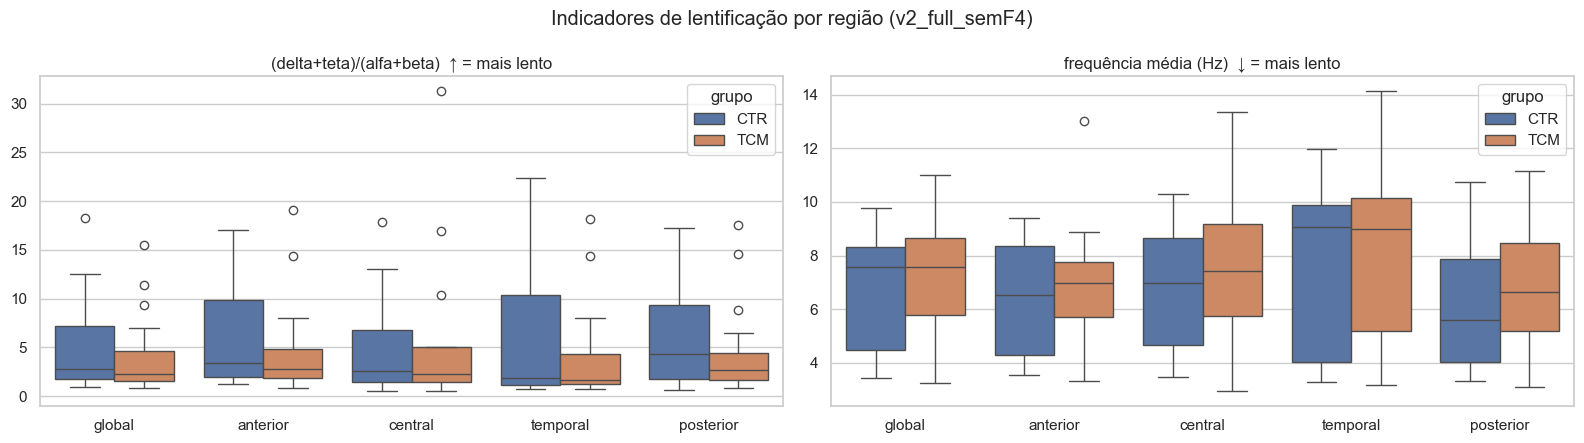

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, ind, t in [(axes[0], "indice_lentificacao", "(delta+teta)/(alfa+beta)  ↑ = mais lento"),
                   (axes[1], "MNF_Hz", "frequência média (Hz)  ↓ = mais lento")]:
    m = idx[[c for c in idx if c.startswith(ind + "|")]].assign(grupo=feat_s.group.values).melt(id_vars="grupo")
    m["regiao"] = m.variable.str.split("|").str[1]
    sns.boxplot(data=m, x="regiao", y="value", hue="grupo", ax=ax)
    ax.set_title(t); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle(f"Indicadores de lentificação por região ({BASE})")
fig.tight_layout(); fig.savefig(FIG / f"{OUT}_lentificacao.png", dpi=120)

## Referência, Exp. 1 (só numéricos) e Exp. 2 (todos)

In [6]:
sweeps = {}
for name, cols in [("ref_classicos", CLASS), ("exp1_numericos", NUM), ("exp2_todos", ALL)]:
    print("rodando", name, len(cols), flush=True)
    sweeps[name] = run_experiment(name, cols)

rodando ref_classicos 360


rodando exp1_numericos 504


rodando exp2_todos 864


## Exp. 3a — seleção não supervisionada
Feita no nível participante sobre os 912 atributos, **sem rótulos**: (1) quase-constantes; (2) Laplacian Score
(quanto o atributo preserva a vizinhança entre participantes; menor = melhor); (3) poda de redundância na ordem do
Laplacian Score (|Spearman| > 0,9 → fica o melhor ranqueado); (4) tamanho do subconjunto (10–160) e k (2–6)
escolhidos pelo maior silhouette do k-means. Viés conhecido: o silhouette tende a favorecer poucos atributos.

In [7]:
SEL_U, sw_sel = select_unsupervised(feat_s[ALL])
print("após poda de redundância:", sw_sel.attrs["n_apos_poda"], "atributos | escolhidos:", len(SEL_U))
display(sw_sel.pivot(index="n_atributos", columns="k", values="silhouette").round(3))
sel_u = pd.DataFrame({"atributo": SEL_U, "familia": [c.split("__")[0] for c in SEL_U],
                      "canal": [c.split("__")[1] for c in SEL_U]})
sel_u["regiao"] = sel_u.canal.map(REGION)
sel_u["origem"] = np.where(sel_u.familia.str.startswith("num_"), "numérico", "clássico")
sel_u["laplacian_score"] = sw_sel.attrs["laplacian"].loc[SEL_U].values
display(sel_u)
print(sel_u.origem.value_counts().to_dict(), "|", sel_u.regiao.value_counts().to_dict())
sweeps["exp3a_selecao_nao_sup"] = run_experiment("exp3a_selecao_nao_sup", SEL_U)

após poda de redundância: 336 atributos | escolhidos: 10


k,2,3,4,5,6
n_atributos,,,,,
10,0.532,0.370,0.339,0.338,0.297
20,0.503,0.357,0.358,0.335,0.281
40,0.430,0.358,0.312,0.233,0.192
80,0.365,0.391,0.258,0.250,0.201
160,0.288,0.328,0.337,0.189,0.141


,atributo,familia,canal,regiao,origem,laplacian_score
0,hjorth_complexity__F7,hjorth_complexity,F7,frontal,clássico,0.339752
1,hjorth_complexity__C3,hjorth_complexity,C3,central,clássico,0.361864
2,ratio_theta_alpha__T6,ratio_theta_alpha,T6,temporal,clássico,0.366909
3,rel_delta__T6,rel_delta,T6,temporal,clássico,0.377820
4,hjorth_complexity__T6,hjorth_complexity,T6,temporal,clássico,0.380646
5,spectral_entropy__T3,spectral_entropy,T3,temporal,clássico,0.406368
6,hjorth_complexity__P4,hjorth_complexity,P4,parietal,clássico,0.414618
7,ratio_theta_alpha__T3,ratio_theta_alpha,T3,temporal,clássico,0.418026
8,num_PSR__T6,num_PSR,T6,temporal,numérico,0.419455
9,hjorth_complexity__T3,hjorth_complexity,T3,temporal,clássico,0.423807


{'clássico': 9, 'numérico': 1} | {'temporal': 7, 'frontal': 1, 'central': 1, 'parietal': 1}


### Tamanho dos clusters — silhouette alto pode ser "poucos participantes extremos contra o resto"

In [8]:
for name in ["ref_classicos", "exp1_numericos", "exp2_todos", "exp3a_selecao_nao_sup"]:
    lab = store[(name, "participante", 2)]["kmeans"]
    ct = pd.crosstab(pd.Series(lab, name="cluster"), feat_s.group.rename("grupo"))
    small = ct.sum(axis=1).idxmin()
    print(f"--- {name}: tamanhos {ct.sum(axis=1).to_dict()} | cluster menor: "
          f"{feat_s.subject[lab == small].tolist()}")
    display(ct)
# amplitude bruta dos participantes no cluster menor do Exp. 3a vs o resto
lab = store[("exp3a_selecao_nao_sup", "participante", 2)]["kmeans"]
small = pd.Series(lab).value_counts().idxmin()
amp = RAW_AMP.loc[feat_s.subject]
print("amplitude bruta (mediana, µV): cluster menor %.1f | resto %.1f | Mann-Whitney p = %.3f" % (
    amp[lab == small].median(), amp[lab != small].median(),
    stats.mannwhitneyu(amp[lab == small], amp[lab != small]).pvalue))

--- ref_classicos: tamanhos {0: 27, 1: 11} | cluster menor: ['P12', 'P20', 'P21', 'P24', 'P36', 'P4', 'P42', 'P43', 'P5', 'P7', 'P8']


grupo,CTR,TCM
cluster,,
0,14,13
1,7,4


--- exp1_numericos: tamanhos {0: 25, 1: 13} | cluster menor: ['P12', 'P15', 'P20', 'P21', 'P24', 'P29', 'P36', 'P4', 'P42', 'P43', 'P5', 'P7', 'P8']


grupo,CTR,TCM
cluster,,
0,13,12
1,8,5


--- exp2_todos: tamanhos {0: 25, 1: 13} | cluster menor: ['P12', 'P15', 'P20', 'P21', 'P24', 'P29', 'P36', 'P4', 'P42', 'P43', 'P5', 'P7', 'P8']


grupo,CTR,TCM
cluster,,
0,13,12
1,8,5


--- exp3a_selecao_nao_sup: tamanhos {0: 28, 1: 10} | cluster menor: ['P12', 'P20', 'P21', 'P24', 'P36', 'P4', 'P42', 'P43', 'P5', 'P7']


grupo,CTR,TCM
cluster,,
0,15,13
1,6,4


amplitude bruta (mediana, µV): cluster menor 38.6 | resto 32.1 | Mann-Whitney p = 0.312


## Exp. 3b — mRMR supervisionado aninhado (referência)
Em cada dobra leave-one-subject-out, o mRMR escolhe 20 atributos usando só os 37 participantes de treino; uma
regressão logística prevê o participante que ficou de fora. A **AUC não tem vazamento**. A frequência de seleção
mostra quais atributos são escolhidos de forma estável. Clusterizar com esses atributos é **otimista**: a escolha
foi guiada pelo diagnóstico, então não é um resultado não supervisionado.

In [9]:
p_mrmr, freq = nested_mrmr_loso(feat_s[ALL], y, m=20)
lo, hi = auc_ci(y, p_mrmr)
print(f"mRMR aninhado + regressão logística: AUC = {roc_auc_score(y, p_mrmr):.3f} [IC95% {lo:.2f}–{hi:.2f}]")
STABLE = list(freq[freq >= 0.5].index)
fr = freq.head(25).rename("freq").reset_index().rename(columns={"index": "atributo"})
fr["regiao"] = fr.atributo.str.split("__").str[1].map(REGION)
display(fr.round(2))
print("atributos escolhidos em >= 50% das dobras:", len(STABLE))
if len(STABLE) >= 2:
    run_experiment("exp3b_mrmr_estaveis_OTIMISTA", STABLE,
                   extra={"mRMR_aninhado_AUC": roc_auc_score(y, p_mrmr), "mRMR_aninhado_IC95": f"{lo:.2f}–{hi:.2f}"})

mRMR aninhado + regressão logística: AUC = 0.473 [IC95% 0.28–0.67]


,atributo,freq,regiao
0,num_LOGD__Cz,1.00,central
1,num_MVAL__Fz,1.00,frontal
2,num_MVAL__T5,0.97,temporal
3,num_TM5__P3,0.95,parietal
4,abs_alpha__Fp2,0.95,frontal
5,num_MVAL__C4,0.95,central
6,num_IAV__F8,0.95,frontal
7,num_PSR__F8,0.87,frontal
8,abs_gamma__P4,0.87,parietal
9,num_MNF__P3,0.82,parietal


atributos escolhidos em >= 50% das dobras: 15


### Onde estão os atributos escolhidos (topografia)

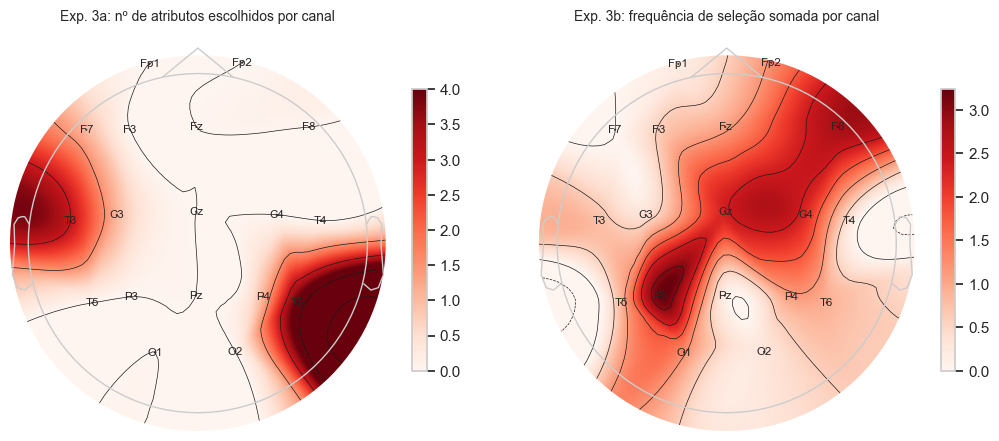

In [10]:
INFO = mne_info(CH)
ch_u = sel_u.canal.value_counts().reindex(CH, fill_value=0)
ch_s = freq.groupby(freq.index.str.split("__").str[1]).sum().reindex(CH, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, v, t in [(axes[0], ch_u, "Exp. 3a: nº de atributos escolhidos por canal"),
                 (axes[1], ch_s, "Exp. 3b: frequência de seleção somada por canal")]:
    im, _ = mne.viz.plot_topomap(v.values.astype(float), INFO, axes=ax, show=False, cmap="Reds", names=CH)
    ax.set_title(t, fontsize=10); plt.colorbar(im, ax=ax, shrink=0.7)
fig.tight_layout(); fig.savefig(FIG / f"{OUT}_topo_selecao.png", dpi=120)

## Placar dos experimentos

In [11]:
res = pd.DataFrame(results)
res.to_csv(ROOT / "reports" / f"{OUT}_experimentos_numericos.csv", index=False)
cols = ["experimento", "n_atributos", "level", "algo", "k_param", "n_clusters", "silhouette", "stability_ARI",
        "grupo_ARI", "grupo_NMI", "grupo_purity", "grupo_p_assoc", "grupo_voto_ARI", "grupo_voto_p_assoc",
        "sexo_ARI", "subject_ARI", "conf_amplitude", "conf_n_janelas", "LR_AUC", "LR_AUC_IC95"]
res[[c for c in cols if c in res]].round(3)

,experimento,n_atributos,level,algo,k_param,n_clusters,silhouette,stability_ARI,grupo_ARI,grupo_NMI,grupo_purity,grupo_p_assoc,grupo_voto_ARI,grupo_voto_p_assoc,sexo_ARI,subject_ARI,conf_amplitude,conf_n_janelas,LR_AUC,LR_AUC_IC95
0,ref_classicos,360,participante,random,2,2,-0.013,NaN,-0.001,0.014,0.579,0.509,NaN,NaN,0.015,NaN,0.440,0.417,0.361,0.19–0.56
1,ref_classicos,360,participante,kmeans,2,2,0.244,0.935,-0.022,0.009,0.553,0.721,NaN,NaN,-0.013,NaN,0.440,0.417,0.361,0.19–0.56
2,ref_classicos,360,participante,agglo_ward,2,2,0.244,0.974,-0.022,0.009,0.553,0.721,NaN,NaN,-0.013,NaN,0.440,0.417,0.361,0.19–0.56
3,ref_classicos,360,participante,gmm,2,2,0.244,0.845,-0.022,0.009,0.553,0.721,NaN,NaN,-0.013,NaN,0.440,0.417,0.361,0.19–0.56
4,ref_classicos,360,participante,spectral,2,2,0.244,NaN,-0.022,0.009,0.553,0.721,NaN,NaN,-0.013,NaN,0.440,0.417,0.361,0.19–0.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,exp3b_mrmr_estaveis_OTIMISTA,15,janela,agglo_ward,2,2,0.229,0.559,-0.014,0.032,0.579,0.000,-0.016,0.355,NaN,0.013,0.428,0.123,0.521,0.34–0.71
81,exp3b_mrmr_estaveis_OTIMISTA,15,janela,gmm,2,2,0.205,0.916,-0.007,0.007,0.579,0.001,-0.016,1.000,NaN,0.006,0.428,0.123,0.521,0.34–0.71
82,exp3b_mrmr_estaveis_OTIMISTA,15,janela,spectral,2,2,0.059,NaN,-0.009,0.005,0.579,0.007,-0.016,1.000,NaN,0.016,0.428,0.123,0.521,0.34–0.71
83,exp3b_mrmr_estaveis_OTIMISTA,15,janela,dbscan,auto,1,NaN,NaN,0.009,0.005,0.585,0.015,0.000,NaN,NaN,0.000,0.428,0.123,0.521,0.34–0.71


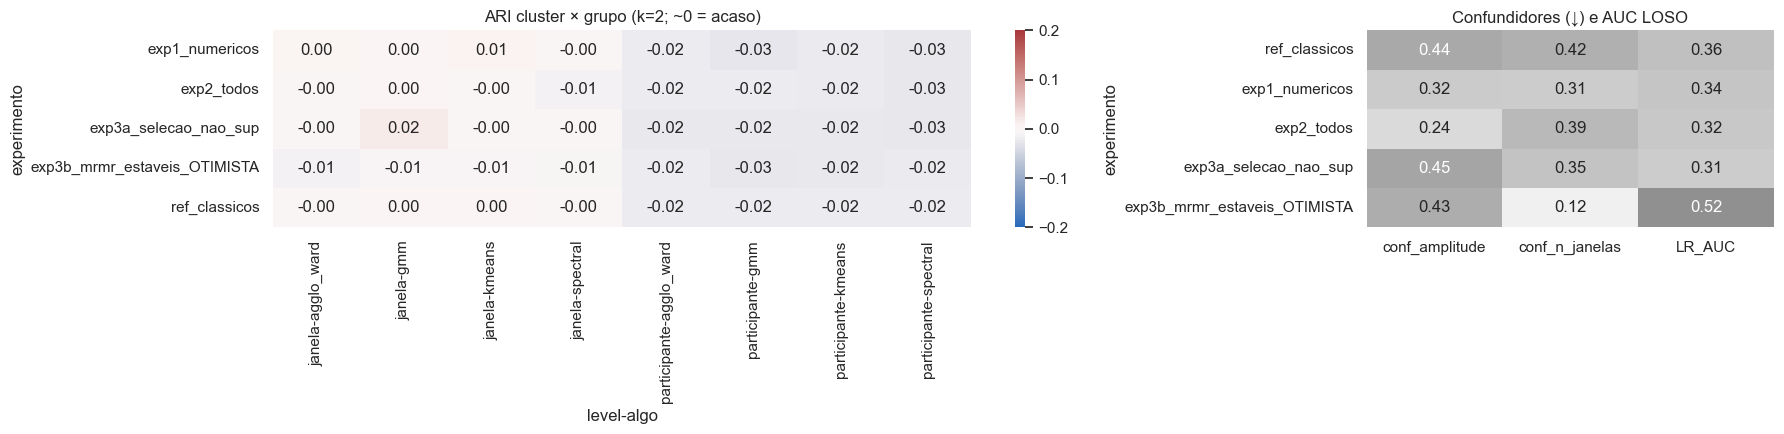

In [12]:
k2 = res[(res.k_param.astype(str) == "2") & res.algo.isin(["kmeans", "agglo_ward", "gmm", "spectral"])]
piv = k2.pivot_table(index="experimento", columns=["level", "algo"], values="grupo_ARI")
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5), gridspec_kw={"width_ratios": [3, 1.4]})
sns.heatmap(piv, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-0.2, vmax=0.2, ax=axes[0])
axes[0].set_title("ARI cluster × grupo (k=2; ~0 = acaso)")
summ = res.drop_duplicates("experimento").set_index("experimento")[["conf_amplitude", "conf_n_janelas", "LR_AUC"]]
sns.heatmap(summ, annot=True, fmt=".2f", cmap="Greys", vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set_title("Confundidores (↓) e AUC LOSO")
fig.tight_layout(); fig.savefig(FIG / f"{OUT}_placar_experimentos.png", dpi=120)

## Varredura de k por experimento (silhouette, nível participante)

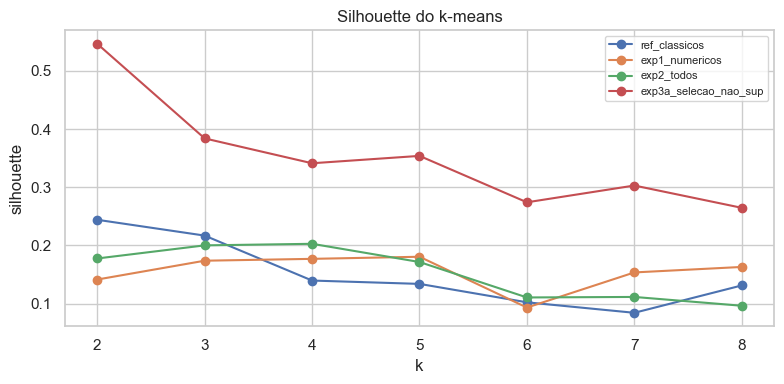

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, sw in sweeps.items():
    ax.plot(sw.k, sw.silhouette, marker="o", label=name)
ax.set_xlabel("k"); ax.set_ylabel("silhouette"); ax.legend(fontsize=8); ax.set_title("Silhouette do k-means")
fig.tight_layout(); fig.savefig(FIG / f"{OUT}_k_sweep.png", dpi=120)